In [ ]:
import numpy as np
from model.helper import *
from model.utils import *

import pandas as pd
import numpy as np
import nibabel as nib
from nilearn.plotting import plot_stat_map, plot_roi
import matplotlib.pyplot as plt

from sklearn.gaussian_process.kernels import RBF, Matern

In [ ]:
import model.BSHE_Gibbs as BSHE_Gibbs
import model.BSHE_VI as BSHE_VI

In [3]:
import nibabel as nib
import nilearn.plotting as plotting
import hcp_utils as hcp

pixdim[1,2,3] should be non-zero; setting 0 dims to 1


In [ ]:
path = f"data/abcd"
time = "baseline"
hemi='left'

In [ ]:
template_file = f'{path}/NDARINV0A4ZDYNL_zstat11.dtseries.nii'
img = nib.load(template_file)
x = img.get_fdata()
from matplotlib.colors import LinearSegmentedColormap
colors = ["blue","cyan","lightgray","lightgray","yellow","#C9182B"]
values = np.array([0, 0.45, 0.49, 0.51, 0.55, 1])
cmap = LinearSegmentedColormap.from_list("gangchen", list(zip(values, colors)))
cmap

In [ ]:
covariates = load_tsv(f'{path}/{time}_covariates.tsv')
covariates["site"] = np.where(covariates["site"] == 22, 1, covariates["site"])
site_ids = covariates["site"].unique()
X = covariates.values
X[:,:3] = (X[:,:3] - X[:,:3].mean(axis=0)) /  X[:,:3].std(axis=0)
X = X[:,:-1]

array([[-0.15205786, -0.77202828,  1.26177711,  1.        ],
       [ 0.93173542,  2.1122726 , -1.17283421,  0.        ],
       [-0.21374664,  1.02932287,  0.31498382,  0.        ],
       ...,
       [ 0.72798928, -0.07442832,  0.4502346 ,  1.        ],
       [-0.31271039,  0.01054253, -1.71385895,  0.        ],
       [ 0.81341748, -0.04117865,  1.39703871,  0.        ]])

In [ ]:
Y = pd.read_csv(f'{path}/{time}_{hemi}_values.csv',header=None)
Y = Y.values

array([[-5.41771, -1.63827,  0.93903, ...,  1.87106,  1.17712,  1.00266],
       [-1.73978, -0.04915,  0.03689, ..., -3.14947, -2.51931, -2.28183],
       [-0.05782, -5.21572,  1.02558, ...,  1.16831, -1.46806,  1.59599],
       ...,
       [-3.36977, -2.96229, -2.81103, ...,  3.1654 , -1.23955,  0.67442],
       [-1.59997, -0.76196, -0.9744 , ...,  0.38938, -1.02684,  0.50451],
       [ 0.53304, -2.90223, -1.54492, ...,  3.65744,  3.55929,  4.33476]])

In [ ]:
S = pd.read_csv(f'{path}/{hemi}_grids.csv')
S = scale(S).values

array([[ 0.92152506, -0.32557936,  0.28456685],
       [ 0.44296363, -0.29125185,  0.97284228],
       [-0.61508271,  0.1754864 ,  0.53600701],
       ...,
       [-0.9164317 , -0.3293014 , -0.41557562],
       [-0.92213674, -0.3290175 , -0.40132069],
       [-0.91292777, -0.34438717, -0.40515974]])

In [10]:
dtype = torch.float32
S = torch.from_numpy(S).to(dtype)
Y = torch.from_numpy(Y).to(dtype)
X = torch.from_numpy(X).to(dtype)

In [ ]:
kernel = Matern(length_scale=0.1, nu=1.5)
L = 700
L_eta = 70
n_chain = 3
burnin = 4000
mcmc_sample = 1000
thin = 1

In [ ]:
model = BSHE_Gibbs.BSHE_Gibbs( Y=Y,
    grids=S, kernel=kernel, X = X,
    L = L, L_eta = L_eta,
    burnin=burnin,
    mcmc_sample=mcmc_sample,
    thin=thin,
    dtype=dtype)
samples = model.run(n_chains=n_chain, parallel = False)

100%|██████████| 5000/5000 [16:38<00:00,  5.01it/s]


Chain 1 finished in 998.50 seconds


100%|██████████| 5000/5000 [16:46<00:00,  4.97it/s]


Chain 2 finished in 1006.60 seconds


100%|██████████| 5000/5000 [16:44<00:00,  4.98it/s]


Chain 3 finished in 1004.77 seconds


In [17]:
voxel_mcmc = samples['alpha'][:,:,:,None] + samples['theta_beta'] @ model.basis.t()
pp = (((( voxel_mcmc > 0) * 1.0).mean(dim=(0,1))) - 0.5) * 2
voxel_select = (pp.abs() > 0.95) * 1
voxel_est= voxel_mcmc.reshape(-1, model.J, model.V).mean(dim=0)
main_eff = voxel_est * voxel_select

/var/folders/_5/n4pn07p954s_9x6bwyrrptq40000gn/T/ipykernel_4754/1740563970.py:9: DeprecationWarning: The `darkness` parameter will be deprecated in release 0.13. We recommend setting `darkness` to None
  fig = plotting.plot_surf_stat_map(


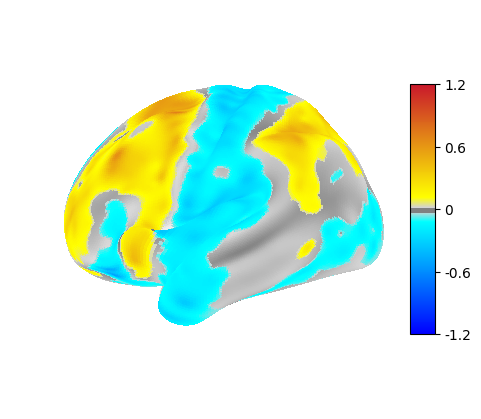

In [ ]:
x[0,:]=np.nan
if hemi == "left":
    x[0,hcp.struct.cortex_left] = main_eff[1]
else:
    x[0,hcp.struct.cortex_right] = main_eff[1]
x_abs = np.abs(x[hcp.struct.cortex])
x_abs_min = x_abs[x_abs > 0].min()
x_abs_max = x_abs[x_abs > 0].max()
fig = plotting.plot_surf_stat_map(
                hcp.mesh.inflated, hcp.cortex_data(x[0]),
                bg_map=hcp.mesh.sulc,cmap=cmap,
                threshold=x_abs_min,colorbar=True,
                vmax=1.2,  vmin=-1.2, 
                hemi=hemi)

In [ ]:
model = BSHE_VI.BSHE_VI(
    Y=Y,grids=S, kernel=kernel, X = X, L = L, L_eta = L_eta,
    dtype=dtype, ELBO_diff_tol=1e-8,max_iter=500000
)
paras, profile = model.run()


iter: 0, ELBO: -2735858.75
Used iter 68 finished in 3.45 seconds


In [ ]:
voxel_mcmc = model.post_samples(n_mcmc=1000)
pp = (((( voxel_mcmc > 0) * 1.0).mean(dim=(0))) - 0.5) * 2
voxel_select = (pp.abs() > 0.99) * 1
voxel_est= voxel_mcmc.reshape(-1, model.J, model.V).mean(dim=0)
main_eff = voxel_est * voxel_select

/var/folders/_5/n4pn07p954s_9x6bwyrrptq40000gn/T/ipykernel_4754/1530802951.py:10: DeprecationWarning: The `darkness` parameter will be deprecated in release 0.13. We recommend setting `darkness` to None
  fig = plotting.plot_surf_stat_map(


<Figure size 1000x500 with 0 Axes>

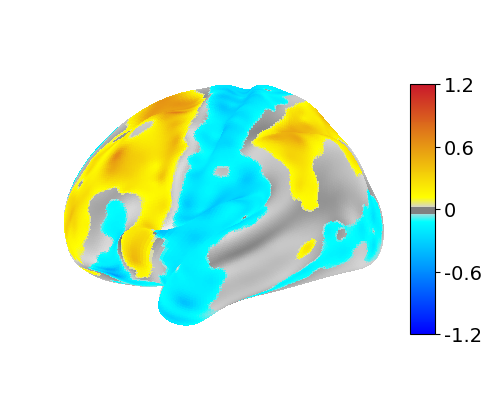

In [34]:
x[0,:]=np.nan
if hemi == "left":
    x[0,hcp.struct.cortex_left] = main_eff[1]
else:
    x[0,hcp.struct.cortex_right] = main_eff[1]
x_abs = np.abs(x[hcp.struct.cortex])
x_abs_min = x_abs[x_abs > 0].min()
x_abs_max = x_abs[x_abs > 0].max()
plt.figure(figsize=(10, 5))
fig = plotting.plot_surf_stat_map(
                hcp.mesh.inflated, hcp.cortex_data(x[0]),
                bg_map=hcp.mesh.sulc,#cmap='cold_hot',
                cmap=cmap,
                threshold=x_abs_min,colorbar=True, 
                vmax=1.2, vmin=-1.2, 
                hemi=hemi)
fig = plt.gcf()
axes = fig.get_axes()
for ax in axes:
    if ax.get_label() == '<colorbar>':
        ax.tick_params(labelsize=14)  # Change font size
plt.show()
fig.savefig(f'plots/{time}_{hemi}_VI_cog_allsite_mean.png', dpi=300)

In [29]:
ppc = model.PPC(n_mcmc=50)

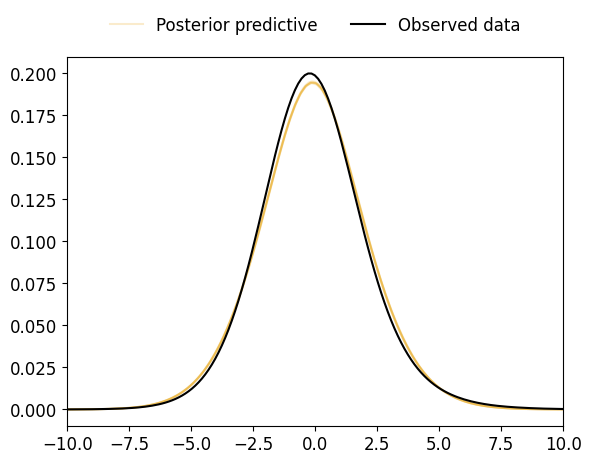

In [ ]:
from fastkde import fastKDE
## takes about 3 mins for 100 draws
for i in range(50):
    density = fastKDE.pdf(ppc[i].reshape(-1),ecf_precision=1) # flat to vector
    density.plot(alpha=0.2, color="#E69F00", label='Posterior predictive' if i == 0 else None)
data_den= fastKDE.pdf(Y.reshape(-1),ecf_precision=1)
data_den.plot(alpha=1.0, color="black", label='Observed data')
plt.xlim(-10, 10)  
plt.ylabel('')
plt.xlabel('')
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)

# Add legend (only one entry for grey lines)
plt.legend(
    loc='upper center',
    fontsize=12,
    bbox_to_anchor=(0.5, 1.15),  # center above axes
    ncol=2,                      # number of legend columns
    frameon=False                # no border
)

plt.savefig(f'plots/narps/BSHE_VI_ppc_J{L}_Jeta{L_eta}.png', dpi=300, bbox_inches='tight')  
plt.show()